<a href="https://colab.research.google.com/github/Temurprojectamity/LAB_KNN/blob/main/Lab_KNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#AIML202
## Lab: K-Nearest Neighbors (KNN) and Instance-Based Classification

**Duration:** 2 hours

| Part | Time | What happens |
|---|---|---|
| Part A - Guided Walkthrough | about 1 hour | We go through every cell together |
| Part B - Graded Exercises | about 30 minutes | You work alone, 3 exercises, 100 marks |

**By the end of this lab you will be able to:**
1. Explain how KNN classifies a new data point.
2. Calculate Euclidean and Manhattan distance.
3. Build a simple KNN classifier by hand and with scikit-learn.
4. Explain why feature scaling matters for KNN.
5. Choose a good value of K.

---
# Part A - Guided Walkthrough

## 1. What is KNN?

**K-Nearest Neighbors (KNN)** is one of the simplest machine learning algorithms.

The idea comes from everyday life: *"Tell me who your neighbours are, and I will tell you who you are."*

To classify a **new** data point, KNN does three things:
1. Measure the **distance** from the new point to every point in the training data.
2. Pick the **K** closest points (the "nearest neighbours").
3. Look at their labels and take a **majority vote**. The most common label wins.

**Why is it called instance-based?**
KNN does not learn formulas or weights during training. It simply **stores** all the training examples (instances). All the real work happens later, when a new point needs a prediction. Because of this, KNN is also called a **lazy learner**.

| | Most models (e.g. Linear Regression) | KNN |
|---|---|---|
| Training | Learn parameters from data | Just store the data |
| Prediction | Use the learned parameters (fast) | Compare with all stored points (slower) |

## 2. Import the libraries

We use only four libraries today:
- `numpy` for numbers and arrays
- `pandas` for tables
- `matplotlib` for simple plots
- `sklearn` (scikit-learn) for ready-made machine learning tools

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

print("Libraries loaded")

Libraries loaded


## 3. A small example dataset

Imagine we have data for 10 students: how many hours they **studied** and how many hours they **slept** before an exam, and whether they **passed** or **failed**.

In [2]:
data = {
    "study_hours": [1, 2, 2, 3, 4, 6, 7, 7, 8, 9],
    "sleep_hours": [4, 5, 3, 6, 4, 7, 6, 8, 7, 8],
    "result":      ["Fail", "Fail", "Fail", "Fail", "Fail",
                    "Pass", "Pass", "Pass", "Pass", "Pass"]
}

students = pd.DataFrame(data)
students

,study_hours,sleep_hours,result
0,1,4,Fail
1,2,5,Fail
2,2,3,Fail
3,3,6,Fail
4,4,4,Fail
5,6,7,Pass
6,7,6,Pass
7,7,8,Pass
8,8,7,Pass
9,9,8,Pass


Now let us draw the students on a graph. Red points failed, green points passed.

A **new student** studied 5 hours and slept 6 hours. We mark this student with a black **X**. Will this student pass or fail?

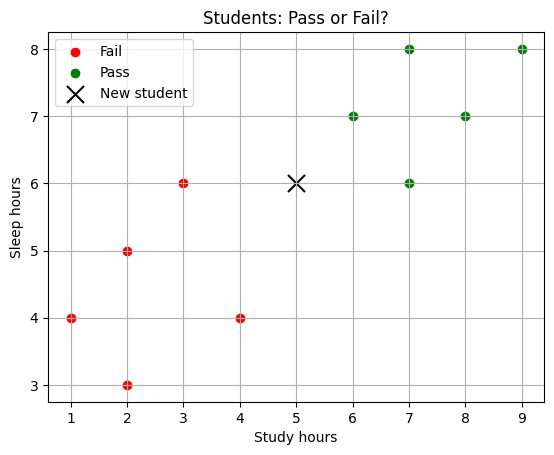

In [3]:
passed = students[students["result"] == "Pass"]
failed = students[students["result"] == "Fail"]

plt.scatter(failed["study_hours"], failed["sleep_hours"], color="red", label="Fail")
plt.scatter(passed["study_hours"], passed["sleep_hours"], color="green", label="Pass")
plt.scatter(5, 6, color="black", marker="x", s=150, label="New student")

plt.xlabel("Study hours")
plt.ylabel("Sleep hours")
plt.title("Students: Pass or Fail?")
plt.legend()
plt.grid(True)
plt.show()

## 4. Distance metrics

KNN needs a way to measure **how close** two points are. This is called a **distance metric**.

Let point A = (x1, y1) and point B = (x2, y2).

### 4.1 Euclidean distance (straight line)
The length of a straight line between A and B, like measuring with a ruler.

$$d = \sqrt{(x_1 - x_2)^2 + (y_1 - y_2)^2}$$

### 4.2 Manhattan distance (city blocks)
The distance if you can only move along streets in a grid (left/right and up/down), like a taxi in a city.

$$d = |x_1 - x_2| + |y_1 - y_2|$$

### 4.3 Minkowski distance (general formula)
A general formula with a number **p**:
- p = 1 gives Manhattan distance
- p = 2 gives Euclidean distance

$$d = \left(|x_1 - x_2|^p + |y_1 - y_2|^p\right)^{1/p}$$

The same formulas work for any number of features: just add one term per feature.

### Example by hand

A = (1, 2) and B = (4, 6)

- Differences: 4 - 1 = 3 and 6 - 2 = 4
- Euclidean: square root of (3 squared + 4 squared) = square root of (9 + 16) = square root of 25 = **5**
- Manhattan: 3 + 4 = **7**

Let us check this with Python.

In [4]:
A = np.array([1, 2])
B = np.array([4, 6])

# Step 1: difference between the two points
diff = A - B
print("Difference:", diff)

# Euclidean: square, add, then square root
euclidean = np.sqrt(np.sum(diff ** 2))
print("Euclidean distance:", euclidean)

# Manhattan: absolute value, then add
manhattan = np.sum(np.abs(diff))
print("Manhattan distance:", manhattan)

Difference: [-3 -4]
Euclidean distance: 5.0
Manhattan distance: 7


We will need these calculations many times, so let us put them inside **functions**.

In [5]:
def euclidean_distance(p1, p2):
    diff = np.array(p1) - np.array(p2)
    return np.sqrt(np.sum(diff ** 2))


def manhattan_distance(p1, p2):
    diff = np.array(p1) - np.array(p2)
    return np.sum(np.abs(diff))


print("Euclidean:", euclidean_distance([1, 2], [4, 6]))
print("Manhattan:", manhattan_distance([1, 2], [4, 6]))

Euclidean: 5.0
Manhattan: 7


## 5. KNN by hand, step by step

Now we classify the new student (5 study hours, 6 sleep hours).

**Step 1:** Calculate the distance from the new student to every student in the table.

In [6]:
new_student = [5, 6]

distances = []
for i in range(len(students)):
    point = [students["study_hours"][i], students["sleep_hours"][i]]
    d = euclidean_distance(new_student, point)
    distances.append(d)

students["distance"] = distances
students

,study_hours,sleep_hours,result,distance
0,1,4,Fail,4.472136
1,2,5,Fail,3.162278
2,2,3,Fail,4.242641
3,3,6,Fail,2.000000
4,4,4,Fail,2.236068
5,6,7,Pass,1.414214
6,7,6,Pass,2.000000
7,7,8,Pass,2.828427
8,8,7,Pass,3.162278
9,9,8,Pass,4.472136


**Step 2:** Sort the table by distance, from smallest to largest.

In [7]:
sorted_students = students.sort_values("distance")
sorted_students

,study_hours,sleep_hours,result,distance
5,6,7,Pass,1.414214
3,3,6,Fail,2.000000
6,7,6,Pass,2.000000
4,4,4,Fail,2.236068
7,7,8,Pass,2.828427
1,2,5,Fail,3.162278
8,8,7,Pass,3.162278
2,2,3,Fail,4.242641
0,1,4,Fail,4.472136
9,9,8,Pass,4.472136


**Step 3:** Take the top K rows (the K nearest neighbours) and count the labels. Let us use K = 3.

In [8]:
K = 3
nearest = sorted_students.head(K)
print(nearest)

print()
print("Vote count:")
print(nearest["result"].value_counts())

   study_hours  sleep_hours result  distance
5            6            7   Pass  1.414214
3            3            6   Fail  2.000000
6            7            6   Pass  2.000000

Vote count:
result
Pass    2
Fail    1
Name: count, dtype: int64


**Step 4:** The label with the most votes is the prediction.

In [9]:
prediction = nearest["result"].value_counts().idxmax()
print("Prediction for the new student with K =", K, ":", prediction)

Prediction for the new student with K = 3 : Pass


### Putting it all together in one function

This function does all four steps. It is a complete (but simple) KNN classifier.

In [10]:
def knn_predict(table, new_point, K):
    # Step 1: distance to every row
    distances = []
    for i in range(len(table)):
        point = [table["study_hours"][i], table["sleep_hours"][i]]
        distances.append(euclidean_distance(new_point, point))

    table = table.copy()
    table["distance"] = distances

    # Step 2 and 3: sort and take the K closest rows
    nearest = table.sort_values("distance").head(K)

    # Step 4: majority vote
    return nearest["result"].value_counts().idxmax()


print(knn_predict(students, [5, 6], K=3))
print(knn_predict(students, [2, 4], K=3))
print(knn_predict(students, [8, 8], K=3))

Pass
Fail
Pass


### Does K change the answer?

Now take a different new student who studied 4 hours and slept 7.5 hours. Try different values of K. Notice that the answer changes: with K = 1 the decision depends on only one neighbour.

**Tip:** For two classes, use an **odd** K (1, 3, 5, ...) so there is never a tie in the vote.

In [11]:
for K in [1, 3, 5, 7]:
    print("K =", K, "->", knn_predict(students, [4, 7.5], K))

K = 1 -> Fail
K = 3 -> Pass
K = 5 -> Pass
K = 7 -> Pass


## 6. KNN with scikit-learn

Writing KNN by hand helps us understand it. In practice we use **scikit-learn**, which does the same steps for us.

We will use the famous **Iris** dataset: 150 flowers, 4 measurements each, and 3 types of flower.

In [12]:
iris = load_iris()
X = iris.data      # features (measurements)
y = iris.target    # labels (flower type: 0, 1, 2)

print("Shape of X:", X.shape)
print("Feature names:", iris.feature_names)
print("Class names:", iris.target_names)

Shape of X: (150, 4)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Class names: ['setosa' 'versicolor' 'virginica']


### The standard 4 steps in scikit-learn

1. **Split** the data into a training set and a test set.
2. **Create** the model.
3. **Fit** (train) the model. For KNN this just stores the training data.
4. **Predict** on the test set and check the **accuracy**.

Accuracy = (number of correct predictions) / (total predictions)

In [13]:
# 1. Split: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Create the model with K = 5
knn = KNeighborsClassifier(n_neighbors=5)

# 3. Fit the model
knn.fit(X_train, y_train)

# 4. Predict and measure accuracy
y_pred = knn.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 1.0


Predict the type of one new flower. The four numbers are: sepal length, sepal width, petal length, petal width (in cm).

In [14]:
new_flower = [[5.0, 3.4, 1.5, 0.2]]
result = knn.predict(new_flower)
print("Predicted class:", iris.target_names[result[0]])

Predicted class: setosa


### Changing the distance metric in scikit-learn

Use the `metric` setting. The default is Euclidean (Minkowski with p = 2).

In [15]:
for m in ["euclidean", "manhattan"]:
    model = KNeighborsClassifier(n_neighbors=5, metric=m)
    model.fit(X_train, y_train)
    acc = accuracy_score(y_test, model.predict(X_test))
    print(m, "accuracy:", acc)

euclidean accuracy: 1.0
manhattan accuracy: 1.0


## 7. Why feature scaling matters

KNN uses distances. If one feature has very large numbers, it will **dominate** the distance and the other features are almost ignored.

**Example:** Two people described by (age in years, salary in dollars):
- Person 1: (25, 50000)
- Person 2: (60, 51000)

The age difference is 35 years (very different people), but the salary difference is 1000. The distance is almost completely decided by salary.

In [16]:
p1 = [25, 50000]
p2 = [60, 51000]
print("Distance:", euclidean_distance(p1, p2))
print("Age difference alone:", 60 - 25)
print("Salary difference alone:", 51000 - 50000)

Distance: 1000.6123125366787
Age difference alone: 35
Salary difference alone: 1000


**Solution: StandardScaler.** It changes every feature so that it has mean 0 and standard deviation 1. After scaling, all features are on the same level.

**Important rule:** Fit the scaler on the **training data only**, then use it to transform both training and test data.

Let us see the effect on the **Wine** dataset. Its features have very different ranges (for example, one feature is around 0.1 and another is around 1000).

In [17]:
wine = load_wine()
X = wine.data
y = wine.target

# Look at the range of a few features
wine_table = pd.DataFrame(X, columns=wine.feature_names)
wine_table[["hue", "alcohol", "magnesium", "proline"]].describe().loc[["min", "max"]]

,hue,alcohol,magnesium,proline
min,0.48,11.03,70.0,278.0
max,1.71,14.83,162.0,1680.0


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Without scaling
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
print("Accuracy WITHOUT scaling:", round(accuracy_score(y_test, knn.predict(X_test)), 3))

# With scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on training data
X_test_scaled = scaler.transform(X_test)         # only transform test data

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
print("Accuracy WITH scaling:   ", round(accuracy_score(y_test, knn.predict(X_test_scaled)), 3))

Accuracy WITHOUT scaling: 0.722
Accuracy WITH scaling:    0.944


Scaling gives a big improvement. **Always scale your features before using KNN.**

## 8. Choosing K

The value of K has a big effect on the model.

| K | What happens |
|---|---|
| Very small (K = 1) | The model follows every single point, including noisy ones. It is perfect on training data but can make mistakes on new data. This is **overfitting**. |
| Very large (K close to the number of points) | The model looks at too many points and almost always predicts the most common class. This is **underfitting**. |
| Medium | Usually the best balance. |

**A simple way to choose K:** try many values, measure the accuracy for each, and pick the K with the best accuracy on data the model has not seen.

The Wine training set has 142 samples. Let us try every K from 1 to 140 on the scaled Wine data.

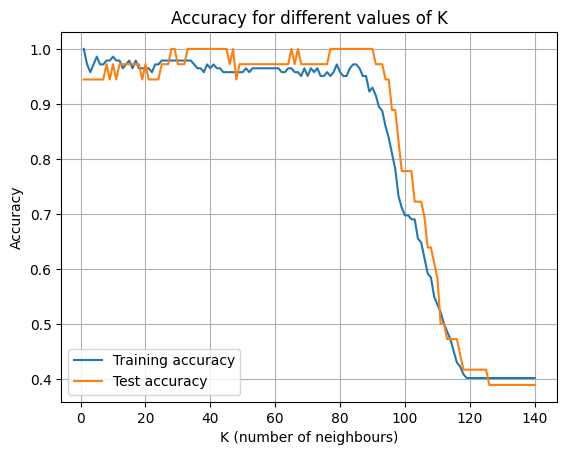

In [19]:
k_values = range(1, 141)
train_scores = []
test_scores = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    train_scores.append(accuracy_score(y_train, model.predict(X_train_scaled)))
    test_scores.append(accuracy_score(y_test, model.predict(X_test_scaled)))

plt.plot(k_values, train_scores, label="Training accuracy")
plt.plot(k_values, test_scores, label="Test accuracy")
plt.xlabel("K (number of neighbours)")
plt.ylabel("Accuracy")
plt.title("Accuracy for different values of K")
plt.legend()
plt.grid(True)
plt.show()

**How to read the plot:**
- At **K = 1**, training accuracy is 1.0 (perfect), because each point is its own nearest neighbour. This does not mean the model is good.
- For a wide range of medium K values, both accuracies stay high. These are good choices.
- After about K = 90, accuracy falls sharply. The model now looks at most of the dataset, so it mostly predicts the largest class. This is underfitting.

Now find the K with the best test accuracy.

In [20]:
best_index = np.argmax(test_scores)
best_k = list(k_values)[best_index]
print("Best K:", best_k)
print("Best test accuracy:", round(test_scores[best_index], 3))

Best K: 28
Best test accuracy: 1.0


**Note:** If several K values give the same best accuracy, `np.argmax` returns the smallest one. In real projects, K is chosen using a separate **validation set** or **cross-validation**, so that the test set stays unseen until the very end. We will learn cross-validation in a later lab.

**Rules of thumb for K:**
- Start with K = 5.
- Use an odd K for two-class problems to avoid ties.
- A common starting guess is K close to the square root of the number of training samples.

## 9. Summary

- KNN classifies a new point by a **majority vote** of its K closest training points.
- It is **instance-based** (lazy): training just stores the data.
- **Euclidean** distance is the straight line; **Manhattan** distance is the sum of absolute differences.
- **Scale your features** (StandardScaler) before using KNN, otherwise large-valued features dominate.
- **Small K** can overfit, **large K** can underfit. Try several values and pick the best one.

**Strengths:** simple, easy to understand, no training time.
**Weaknesses:** slow prediction on large datasets, sensitive to scaling and to irrelevant features.

---
# Part B - Graded Exercises (100 marks, 30 minutes)

**Instructions**
- Work on your own.
- Write your code where you see `# YOUR CODE HERE` and replace each `None` with your answer.
- Run every cell, so your output is visible.
- Marks for each part are shown in brackets.
- You may scroll up and use the code from Part A as a guide.

| Exercise | Topic | Marks |
|---|---|---|
| 1 | Distance metrics | 30 |
| 2 | KNN classifier with scaling | 35 |
| 3 | Choosing the best K | 35 |
| | **Total** | **100** |

Run the cell below first.

In [21]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

print("Ready")

Ready


## Exercise 1: Distance Metrics (30 marks)

You are given two points with **three** features each:

P = (2, 5, 1) and Q = (6, 2, 4)

**(a)** Calculate the **Euclidean** distance between P and Q using NumPy. **[10 marks]**

In [22]:
P = np.array([2, 5, 1])
Q = np.array([6, 2, 4])

# YOUR CODE HERE
differance=P-Q
euclidean = np.sqrt(np.sum(differance ** 2))

print("Euclidean distance:", euclidean)

Euclidean distance: 5.830951894845301


**(b)** Calculate the **Manhattan** distance between P and Q using NumPy. **[10 marks]**

In [23]:
# YOUR CODE HERE
manhattan = np.sum(np.abs(differance))

print("Manhattan distance:", manhattan)

Manhattan distance: 10


**(c)** A query point is `query = (3, 3, 3)`. Below are four stored points. Using **Euclidean** distance, find which stored point is the **nearest neighbour** of the query. Print the distance to each point and the name of the nearest one. **[10 marks]**

In [31]:
query = np.array([3, 3, 3])

points = {
    "A": np.array([1, 1, 1]),
    "B": np.array([4, 2, 3]),
    "C": np.array([6, 6, 6]),
    "D": np.array([3, 5, 2])
}

nearest_name = None
smallest_distance = 1000000   # start with a very big number

for name in points:
    # YOUR CODE HERE: calculate the distance from query to points[name]
    d = euclidean_distance(query, points[name])
    print(name, "distance:", d)

    # YOUR CODE HERE: if d is smaller than smallest_distance, update
    # smallest_distance and nearest_name
    if d < smallest_distance:
        smallest_distance = d
        nearest_name = name


print("Nearest neighbour:", nearest_name)

A distance: 3.4641016151377544
B distance: 1.4142135623730951
C distance: 5.196152422706632
D distance: 2.23606797749979
Nearest neighbour: B


## Exercise 2: KNN Classifier with Scaling (35 marks)

We will use the **Breast Cancer** dataset from scikit-learn. Each row is a patient sample with 30 measurements. The label is 0 (malignant) or 1 (benign).

The data is loaded and split for you below. Run this cell.

In [32]:
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

Training samples: 455
Test samples: 114
Number of features: 30


**(a)** Create a KNN model with **K = 5**, train it on the **unscaled** data, and print the test accuracy. **[10 marks]**

In [34]:
# YOUR CODE HERE
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

accuracy_unscaled = accuracy_score(y_test, knn.predict(X_test))
print("Accuracy without scaling:", accuracy_unscaled)

Accuracy without scaling: 0.9122807017543859


**(b)** Scale the data with `StandardScaler`. Remember: **fit** on the training data, then **transform** both training and test data. **[10 marks]**

In [36]:
scaler = StandardScaler()

# YOUR CODE HERE
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling done")

Scaling done


**(c)** Train a new KNN model with **K = 5** on the **scaled** data and print the test accuracy. Then train one more model with K = 5 and `metric="manhattan"` on the scaled data and print its accuracy. **[15 marks]**

In [37]:
# YOUR CODE HERE: Euclidean (default) on scaled data
accuracy_scaled = accuracy_score(y_test, knn.predict(X_test_scaled))
print("Accuracy with scaling (Euclidean):", accuracy_scaled)

# YOUR CODE HERE: Manhattan on scaled data
accuracy_manhattan = accuracy_score(y_test, KNeighborsClassifier(n_neighbors=5, metric="manhattan").fit(X_train_scaled, y_train).predict(X_test_scaled))
print("Accuracy with scaling (Manhattan):", accuracy_manhattan)

Accuracy with scaling (Euclidean): 0.631578947368421
Accuracy with scaling (Manhattan): 0.9649122807017544


## Exercise 3: Choosing the Best K (35 marks)

Use the **scaled** Breast Cancer data from Exercise 2.

**(a)** Try every **odd** K from 1 to 29 (1, 3, 5, ..., 29). For each K, train a model on the scaled training data and save the test accuracy in the list `accuracies`. **[15 marks]**

Hint: `range(1, 30, 2)` gives 1, 3, 5, ..., 29.

In [47]:
k_values = range(1, 30, 2)
accuracies = []

for k in k_values:
    # Create and train the model on scaled training data
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)

    # Test on scaled test data and record accuracy
    acc = accuracy_score(y_test, model.predict(X_test_scaled))
    accuracies.append(acc)

print(accuracies)

[0.9385964912280702, 0.9824561403508771, 0.956140350877193, 0.9736842105263158, 0.9736842105263158, 0.9736842105263158, 0.9736842105263158, 0.9736842105263158, 0.9824561403508771, 0.9736842105263158, 0.9649122807017544, 0.956140350877193, 0.9649122807017544, 0.9473684210526315, 0.9473684210526315]


**(b)** Draw a line plot with K on the x-axis and accuracy on the y-axis. Add axis labels and a title. Then print the best K and its accuracy. **[10 marks]**

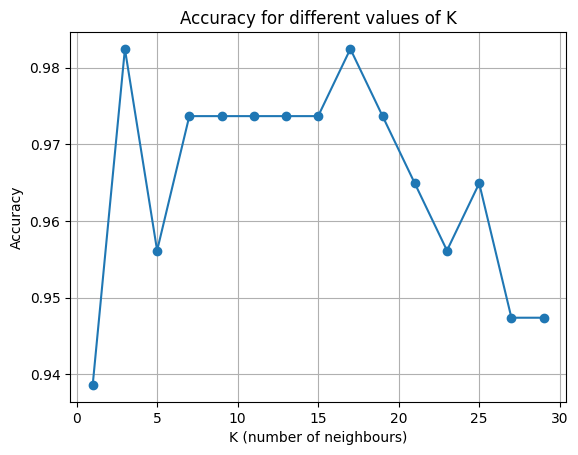

Best K: 3
Best accuracy: 0.9825


In [48]:
# YOUR CODE HERE: line plot
plt.plot(k_values, accuracies, marker='o')
plt.xlabel("K (number of neighbours)")
plt.ylabel("Accuracy")
plt.title("Accuracy for different values of K")
plt.grid(True)
plt.show()

# YOUR CODE HERE: best K
best_index = np.argmax(accuracies)
best_k = list(k_values)[best_index]
best_accuracy = accuracies[best_index]
print("Best K:", best_k)
print("Best accuracy:", round(best_accuracy, 4))

**(c)** Answer in 1 or 2 sentences each, in the cell below. **[10 marks]**

1. Why is K = 1 usually **not** a good choice, even if it gives high training accuracy? (5 marks)
2. Why did we use only **odd** values of K in this exercise? (5 marks)

**Your answers:**

1.Using K = 1 leads to overfitting because the model lacks generalization power.


2.Odd values of K are used to avoid ties during the majority voting process.
